In [1]:
!pip -q install pandas numpy matplotlib seaborn scikit-learn shap

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
#Load dataset
from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Saving dengue_cases.csv to dengue_cases.csv
Dataset loaded successfully!
Dataset shape: (26338, 7)


,District,Number_of_Cases,Week_Start_Date,Month,Year,Week,Week_End_Date
0,Ampara,0,12/23/2006,12,2006,52,12/29/2006
1,Anuradhapura,4,12/23/2006,12,2006,52,12/29/2006
2,Badulla,2,12/23/2006,12,2006,52,12/29/2006
3,Batticaloa,0,12/23/2006,12,2006,52,12/29/2006
4,Colombo,71,12/23/2006,12,2006,52,12/29/2006


In [4]:
#Inspect the dataset
# Dataset information
print("Dataset Information:")
df.info()

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Statistical summary
print("\nStatistical Summary:")
display(df.describe(include="all"))

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Duplicate records
print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26338 entries, 0 to 26337
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   District         26338 non-null  object
 1   Number_of_Cases  26338 non-null  int64 
 2   Week_Start_Date  26338 non-null  object
 3   Month            26338 non-null  int64 
 4   Year             26338 non-null  int64 
 5   Week             26338 non-null  int64 
 6   Week_End_Date    26338 non-null  object
dtypes: int64(4), object(3)
memory usage: 1.4+ MB

Missing Values:
District           0
Number_of_Cases    0
Week_Start_Date    0
Month              0
Year               0
Week               0
Week_End_Date      0
dtype: int64

Statistical Summary:


,District,Number_of_Cases,Week_Start_Date,Month,Year,Week,Week_End_Date
count,26338,26338.000000,26338,26338.000000,26338.000000,26338.000000,26338
unique,27,NaN,993,NaN,NaN,NaN,993
top,Ampara,NaN,8/17/2024,NaN,NaN,NaN,8/23/2024
freq,1013,NaN,52,NaN,NaN,NaN,52
mean,NaN,32.364720,NaN,6.430405,2016.208292,26.262586,NaN
std,NaN,81.391393,NaN,3.459654,5.632394,15.067695,NaN
min,NaN,0.000000,NaN,1.000000,2006.000000,1.000000,NaN
25%,NaN,2.000000,NaN,3.000000,2011.000000,13.000000,NaN
50%,NaN,9.000000,NaN,6.000000,2016.000000,26.000000,NaN
75%,NaN,30.000000,NaN,9.000000,2021.000000,39.000000,NaN



Column Names:
['District', 'Number_of_Cases', 'Week_Start_Date', 'Month', 'Year', 'Week', 'Week_End_Date']

Duplicate Rows:
3


In [5]:
#Check the dataset visually
print("Dataset Preview:")
display(df.head(10))

print("Dataset Dimensions:")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset Preview:


,District,Number_of_Cases,Week_Start_Date,Month,Year,Week,Week_End_Date
0,Ampara,0,12/23/2006,12,2006,52,12/29/2006
1,Anuradhapura,4,12/23/2006,12,2006,52,12/29/2006
2,Badulla,2,12/23/2006,12,2006,52,12/29/2006
3,Batticaloa,0,12/23/2006,12,2006,52,12/29/2006
4,Colombo,71,12/23/2006,12,2006,52,12/29/2006
5,Galle,1,12/23/2006,12,2006,52,12/29/2006
6,Gampaha,12,12/23/2006,12,2006,52,12/29/2006
7,Hambantota,1,12/23/2006,12,2006,52,12/29/2006
8,Jaffna,0,12/23/2006,12,2006,52,12/29/2006
9,Kalmunai,0,12/23/2006,12,2006,52,12/29/2006


Dataset Dimensions:
Rows: 26338
Columns: 7


In [6]:
#Remove duplicates and handle missing values
# Create a copy of the original dataset
df_clean = df.copy()

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Convert date columns
df_clean["Week_Start_Date"] = pd.to_datetime(
    df_clean["Week_Start_Date"], errors="coerce"
)

df_clean["Week_End_Date"] = pd.to_datetime(
    df_clean["Week_End_Date"], errors="coerce"
)

# Remove rows with missing essential values
df_clean = df_clean.dropna(
    subset=[
        "District",
        "Number_of_Cases",
        "Week_Start_Date"
    ]
)

# Remove invalid negative case counts
df_clean = df_clean[
    df_clean["Number_of_Cases"] >= 0
]

print("Cleaned Dataset Shape:", df_clean.shape)
print("\nMissing Values:")
print(df_clean.isnull().sum())

display(df_clean.head())

Cleaned Dataset Shape: (26335, 7)

Missing Values:
District           0
Number_of_Cases    0
Week_Start_Date    0
Month              0
Year               0
Week               0
Week_End_Date      0
dtype: int64


,District,Number_of_Cases,Week_Start_Date,Month,Year,Week,Week_End_Date
0,Ampara,0,2006-12-23,12,2006,52,2006-12-29
1,Anuradhapura,4,2006-12-23,12,2006,52,2006-12-29
2,Badulla,2,2006-12-23,12,2006,52,2006-12-29
3,Batticaloa,0,2006-12-23,12,2006,52,2006-12-29
4,Colombo,71,2006-12-23,12,2006,52,2006-12-29


In [7]:
#Prepare features for prediction
# Sort records chronologically
df_clean = df_clean.sort_values(
    ["District", "Week_Start_Date"]
).copy()

# Create historical features for each district
group = df_clean.groupby("District")["Number_of_Cases"]

df_clean["Cases_Last_Week"] = group.shift(1)
df_clean["Cases_Two_Weeks_Ago"] = group.shift(2)
df_clean["Cases_Three_Weeks_Ago"] = group.shift(3)

# Remove records without enough historical data
df_model = df_clean.dropna(
    subset=[
        "Cases_Last_Week",
        "Cases_Two_Weeks_Ago",
        "Cases_Three_Weeks_Ago"
    ]
).copy()

# Select input features
features = [
    "District",
    "Month",
    "Year",
    "Week",
    "Cases_Last_Week",
    "Cases_Two_Weeks_Ago",
    "Cases_Three_Weeks_Ago"
]

X = df_model[features]
y = df_model["Number_of_Cases"]

# Encode district names
X = pd.get_dummies(
    X,
    columns=["District"],
    dtype=int
)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())

Features shape: (26256, 32)
Target shape: (26256,)


,Month,Year,Week,Cases_Last_Week,Cases_Two_Weeks_Ago,Cases_Three_Weeks_Ago,District_Ampara,District_Anuradhapura,District_Badulla,District_Batticaloa,...,District_Matale,District_Matara,District_Monaragala,District_Mullaitivu,District_Nuwara Eliya,District_Polonnaruwa,District_Puttalam,District_Ratnapura,District_Trincomalee,District_Vavuniya
78,1,2007,3,0.0,0.0,0.0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
104,1,2007,4,0.0,0.0,0.0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
130,1,2007,5,0.0,0.0,0.0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
156,2,2007,6,0.0,0.0,0.0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
182,2,2007,7,0.0,0.0,0.0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [8]:
#Split the dataset
# Sort by date across all districts
df_model = df_model.sort_values(
    "Week_Start_Date"
)

# Rebuild X and y in chronological order
X = pd.get_dummies(
    df_model[features],
    columns=["District"],
    dtype=int
)

y = df_model["Number_of_Cases"]

# Split into 70% training, 15% validation, 15% testing
n = len(X)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train = X.iloc[:train_end]
X_val = X.iloc[train_end:val_end]
X_test = X.iloc[val_end:]

y_train = y.iloc[:train_end]
y_val = y.iloc[train_end:val_end]
y_test = y.iloc[val_end:]

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

Training samples: 18379
Validation samples: 3938
Testing samples: 3939


In [9]:
#Check the results
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nMissing values in features:")
print(X.isnull().sum().sum())

print("\nMissing values in target:")
print(y.isnull().sum())

Training: (18379, 32)
Validation: (3938, 32)
Testing: (3939, 32)

Missing values in features:
0

Missing values in target:
0


In [10]:
#Step 3 — Train the Extra Trees Regressor
#Improve the time-based split
# Split data by unique reporting weeks
dates = sorted(df_model["Week_Start_Date"].unique())

train_cut = int(len(dates) * 0.70)
val_cut = int(len(dates) * 0.85)

train_dates = dates[:train_cut]
val_dates = dates[train_cut:val_cut]
test_dates = dates[val_cut:]

train_mask = df_model["Week_Start_Date"].isin(train_dates)
val_mask = df_model["Week_Start_Date"].isin(val_dates)
test_mask = df_model["Week_Start_Date"].isin(test_dates)

X_train = X.loc[train_mask]
X_val = X.loc[val_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_val = y.loc[val_mask]
y_test = y.loc[test_mask]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("Training ends:", max(train_dates))
print("Validation starts:", min(val_dates))
print("Testing starts:", min(test_dates))

Training: (18431, 32)
Validation: (3926, 32)
Testing: (3899, 32)
Training ends: 2020-08-15 00:00:00
Validation starts: 2020-08-22 00:00:00
Testing starts: 2023-07-29 00:00:00


In [11]:
#Import the algorithm
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

print("Extra Trees Regressor imported successfully!")

Extra Trees Regressor imported successfully!


In [12]:
#Train the model
# Create Extra Trees model
model = ExtraTreesRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Train using training data
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [13]:
#Evaluate validation performance
# Predict validation data
y_val_pred = model.predict(X_val)

# Calculate metrics
mae = mean_absolute_error(y_val, y_val_pred)
rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))
r2 = r2_score(y_val, y_val_pred)

print("Extra Trees Regressor - Validation Results")
print("----------------------------------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

Extra Trees Regressor - Validation Results
----------------------------------------
MAE: 13.11
RMSE: 42.3
R2 Score: 0.4057


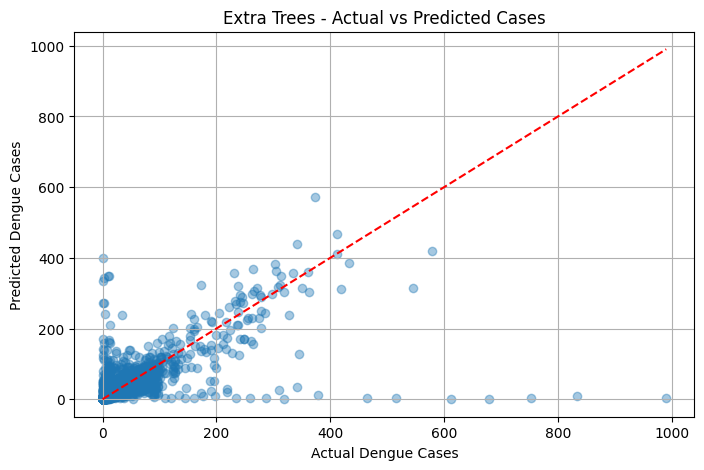

In [14]:
#Visualise actual vs predicted cases
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    y_val,
    y_val_pred,
    alpha=0.4
)

max_cases = max(y_val.max(), y_val_pred.max())

plt.plot(
    [0, max_cases],
    [0, max_cases],
    "r--"
)

plt.xlabel("Actual Dengue Cases")
plt.ylabel("Predicted Dengue Cases")
plt.title("Extra Trees - Actual vs Predicted Cases")
plt.grid(True)
plt.show()

In [15]:
#Step 4: Final Model Evaluation.
#Step 4.1 — Evaluate the model using test data
# Final model evaluation on unseen test data

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

# Predict test data
y_test_pred = model.predict(X_test)

# Calculate evaluation metrics
test_mae = mean_absolute_error(y_test, y_test_pred)
test_rmse = np.sqrt(
    mean_squared_error(y_test, y_test_pred)
)
test_r2 = r2_score(y_test, y_test_pred)

print("FINAL MODEL EVALUATION")
print("----------------------")
print("MAE:", round(test_mae, 2))
print("RMSE:", round(test_rmse, 2))
print("R2 Score:", round(test_r2, 4))

FINAL MODEL EVALUATION
----------------------
MAE: 13.07
RMSE: 35.52
R2 Score: 0.7701


In [16]:
#Step 4.2 — Create an evaluation results table
# Compare validation and testing results

results = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2 Score"],
    "Validation": [mae, rmse, r2],
    "Testing": [test_mae, test_rmse, test_r2]
})

display(results.round(3))

,Metric,Validation,Testing
0,MAE,13.112,13.067
1,RMSE,42.302,35.516
2,R2 Score,0.406,0.770


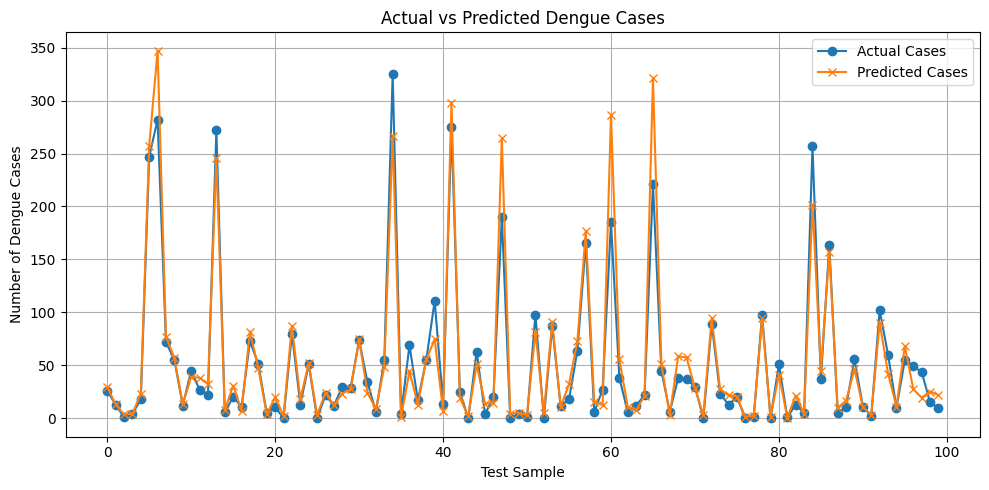

In [17]:
#Step 4.3 — Create a prediction comparison graph
# Actual vs predicted dengue cases

plt.figure(figsize=(10, 5))

sample_size = min(100, len(y_test))

plt.plot(
    np.arange(sample_size),
    y_test.iloc[:sample_size].values,
    label="Actual Cases",
    marker="o"
)

plt.plot(
    np.arange(sample_size),
    y_test_pred[:sample_size],
    label="Predicted Cases",
    marker="x"
)

plt.title("Actual vs Predicted Dengue Cases")
plt.xlabel("Test Sample")
plt.ylabel("Number of Dengue Cases")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [18]:
#Step 4.4 — Save the results
# Save evaluation metrics
results.to_csv(
    "model_evaluation_results.csv",
    index=False
)

print("Evaluation results saved successfully!")

Evaluation results saved successfully!


,Feature,Importance
3,Cases_Last_Week,0.512773
4,Cases_Two_Weeks_Ago,0.258484
5,Cases_Three_Weeks_Ago,0.158539
10,District_Colombo,0.022823
2,Week,0.014824
0,Month,0.013848
1,Year,0.007072
12,District_Gampaha,0.003830
17,District_Kandy,0.001631
20,District_Kurunegala,0.001065


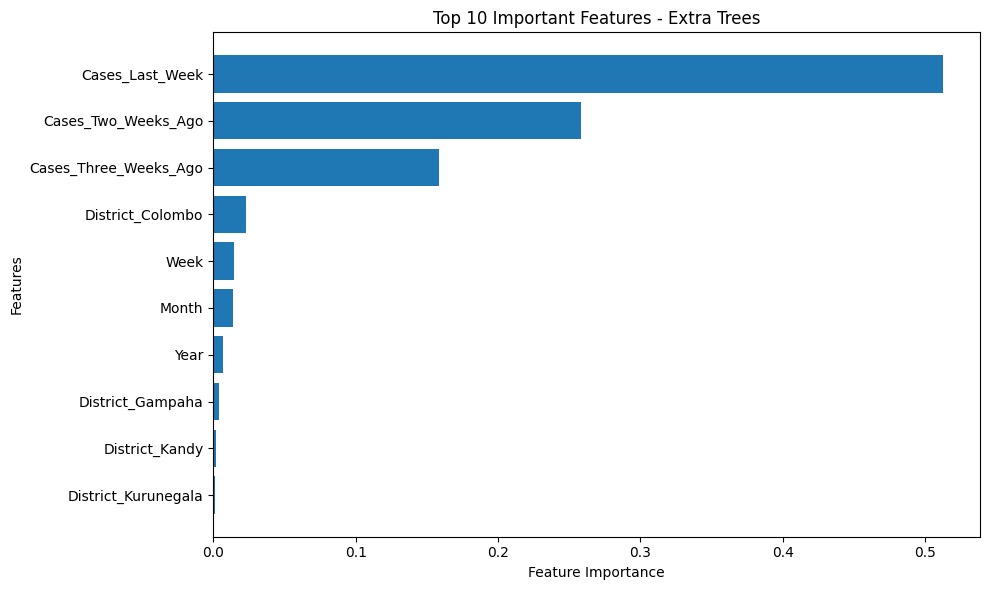

In [19]:
#Step 5: Explainable AI (XAI)
#Step 5.1 — Feature Importance
import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importance
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model.feature_importances_
})

# Sort features
importance = importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 10 features
display(importance.head(10))

# Plot
plt.figure(figsize=(10, 6))

plt.barh(
    importance["Feature"].head(10)[::-1],
    importance["Importance"].head(10)[::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 10 Important Features - Extra Trees")

plt.tight_layout()
plt.savefig("feature_importance.png", dpi=300)
plt.show()

In [20]:
#Step 5.2 — Generate SHAP explanations
import shap
import numpy as np

# Use a small sample to save time
X_shap = X_test.sample(
    n=min(100, len(X_test)),
    random_state=42
)

# Create SHAP explainer
explainer = shap.TreeExplainer(model)

# Calculate SHAP values
shap_values = explainer.shap_values(X_shap)

print("SHAP values calculated successfully!")

SHAP values calculated successfully!


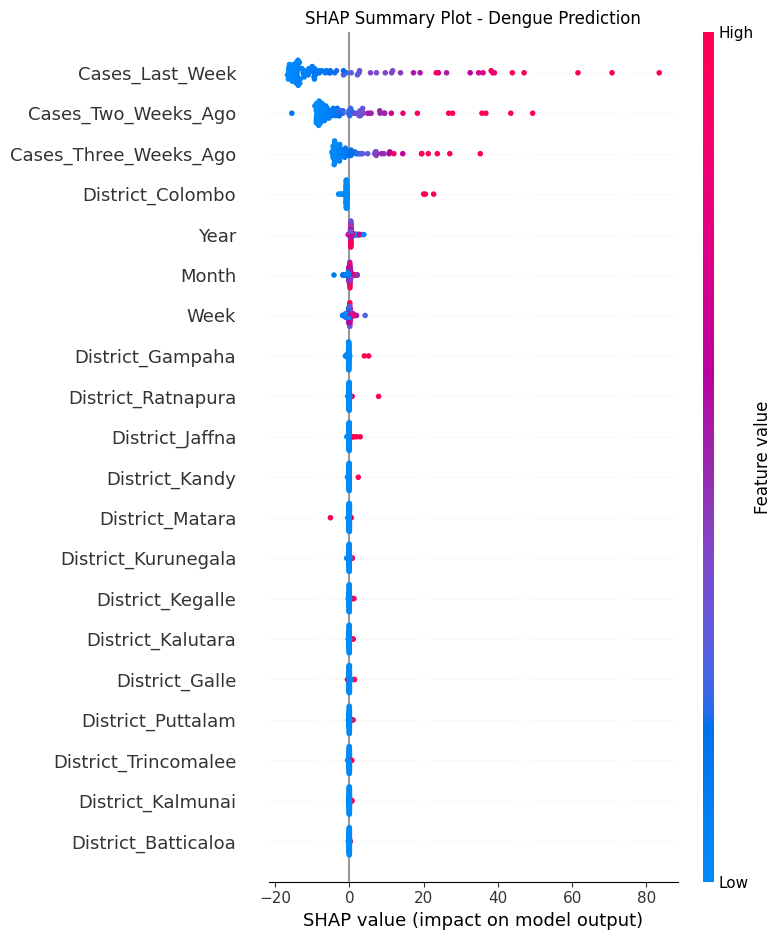

In [21]:
#Step 5.3 — SHAP Summary Plot
# SHAP summary plot
shap.summary_plot(
    shap_values,
    X_shap,
    show=False
)

plt.title("SHAP Summary Plot - Dengue Prediction")
plt.tight_layout()
plt.savefig(
    "shap_summary.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

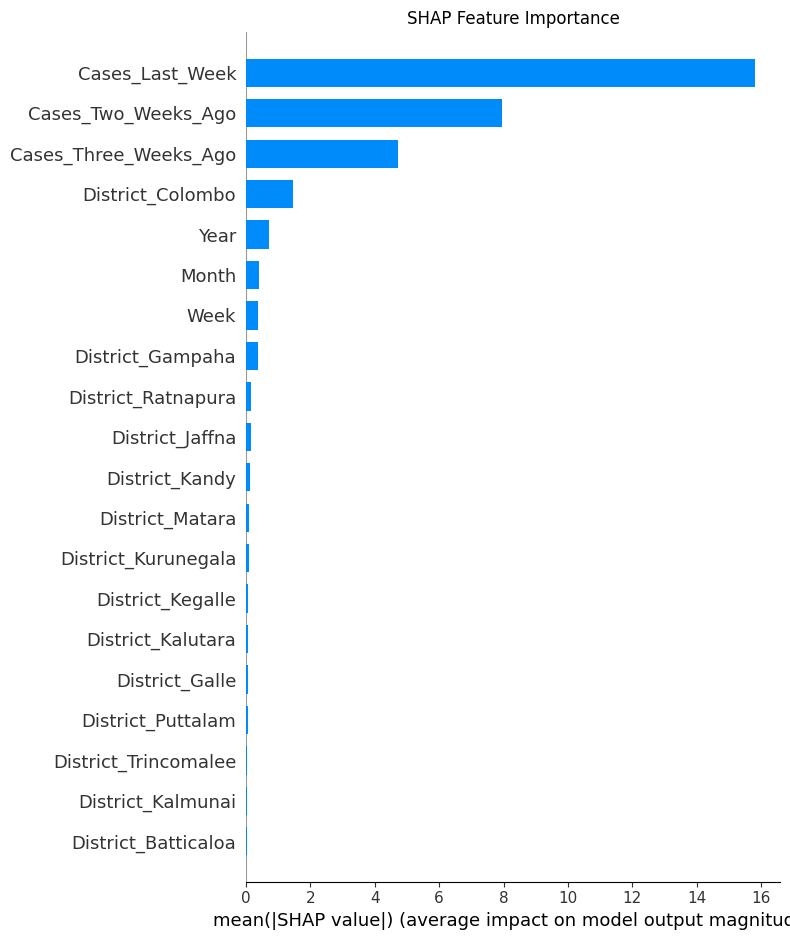

In [22]:
#Step 5.4 — SHAP Feature Importance Plot
shap.summary_plot(
    shap_values,
    X_shap,
    plot_type="bar",
    show=False
)

plt.title("SHAP Feature Importance")
plt.tight_layout()

plt.savefig(
    "shap_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
#Step 5.5 — Save the feature importance results
importance.to_csv(
    "feature_importance.csv",
    index=False
)

print("XAI results saved successfully!")

XAI results saved successfully!


In [24]:
#Step 6.1 — Generate a summary of your actual results
print("=== FINAL MODEL RESULTS ===")

print("Algorithm: Extra Trees Regressor")
print("Dataset: Sri Lankan Dengue Cases")
print("Original Rows:", len(df))
print("Model Rows:", len(df_model))

print("\n=== TEST PERFORMANCE ===")
print("MAE:", round(test_mae, 2))
print("RMSE:", round(test_rmse, 2))
print("R2 Score:", round(test_r2, 4))

print("\n=== TOP 10 IMPORTANT FEATURES ===")
display(importance.head(10))

=== FINAL MODEL RESULTS ===
Algorithm: Extra Trees Regressor
Dataset: Sri Lankan Dengue Cases
Original Rows: 26338
Model Rows: 26256

=== TEST PERFORMANCE ===
MAE: 13.07
RMSE: 35.52
R2 Score: 0.7701

=== TOP 10 IMPORTANT FEATURES ===


,Feature,Importance
3,Cases_Last_Week,0.512773
4,Cases_Two_Weeks_Ago,0.258484
5,Cases_Three_Weeks_Ago,0.158539
10,District_Colombo,0.022823
2,Week,0.014824
0,Month,0.013848
1,Year,0.007072
12,District_Gampaha,0.003830
17,District_Kandy,0.001631
20,District_Kurunegala,0.001065


In [25]:
#Step 6.2 — Check your SHAP interpretation
import numpy as np
import pandas as pd

shap_importance = pd.DataFrame({
    "Feature": X_shap.columns,
    "Mean_Absolute_SHAP": np.abs(shap_values).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
)

display(shap_importance.head(10))

,Feature,Mean_Absolute_SHAP
3,Cases_Last_Week,15.797525
4,Cases_Two_Weeks_Ago,7.943698
5,Cases_Three_Weeks_Ago,4.736310
10,District_Colombo,1.458811
1,Year,0.715771
0,Month,0.396284
2,Week,0.375114
12,District_Gampaha,0.370691
29,District_Ratnapura,0.157138
14,District_Jaffna,0.147715


In [26]:

print("FINAL MODEL PERFORMANCE")
print("-----------------------")
print("MAE:", round(test_mae, 2))
print("RMSE:", round(test_rmse, 2))
print("R2 Score:", round(test_r2, 4))

print("\nDataset rows:", len(df))
print("Model rows:", len(df_model))

FINAL MODEL PERFORMANCE
-----------------------
MAE: 13.07
RMSE: 35.52
R2 Score: 0.7701

Dataset rows: 26338
Model rows: 26256


In [27]:
#Final checks before preparing the PDF report
# Check gaps between reporting weeks
check = df_clean.sort_values(
    ["District", "Week_Start_Date"]
).copy()

check["Previous_Date"] = check.groupby(
    "District"
)["Week_Start_Date"].shift(1)

check["Gap_Days"] = (
    check["Week_Start_Date"] - check["Previous_Date"]
).dt.days

print("Non-consecutive weekly records:")
print(
    ((check["Gap_Days"].notna()) &
     (check["Gap_Days"] != 7)).sum()
)

print("\nSample irregular records:")
display(
    check.loc[
        check["Gap_Days"].notna() &
        (check["Gap_Days"] != 7),
        ["District", "Week_Start_Date", "Gap_Days"]
    ].head(10)
)

Non-consecutive weekly records:
2676

Sample irregular records:


,District,Week_Start_Date,Gap_Days
1144,Ampara,2007-11-03,14.0
1170,Ampara,2007-11-03,0.0
2366,Ampara,2008-08-20,4.0
2262,Ampara,2008-08-23,3.0
2392,Ampara,2008-09-27,14.0
2730,Ampara,2008-12-26,6.0
2756,Ampara,2008-12-27,1.0
2912,Ampara,2009-02-14,14.0
2938,Ampara,2009-02-14,0.0
2964,Ampara,2009-02-28,14.0


In [28]:
#Step 7 — Correct the weekly data
# Create consistent calendar-week records

weekly = df_clean.copy()

# Assign each record to a calendar week
weekly["Week_Date"] = (
    weekly["Week_Start_Date"]
    .dt.to_period("W-SAT")
    .dt.start_time
)

# Aggregate records within the same district and week
weekly = (
    weekly.groupby(
        ["District", "Week_Date"],
        as_index=False
    )["Number_of_Cases"]
    .sum()
)

weekly = weekly.sort_values(
    ["District", "Week_Date"]
)

print("Weekly dataset created!")
print("Rows:", len(weekly))

display(weekly.head(10))

Weekly dataset created!
Rows: 25376


,District,Week_Date,Number_of_Cases
0,Ampara,2006-12-17,0
1,Ampara,2006-12-24,0
2,Ampara,2006-12-31,0
3,Ampara,2007-01-07,0
4,Ampara,2007-01-14,0
5,Ampara,2007-01-21,0
6,Ampara,2007-01-28,0
7,Ampara,2007-02-04,0
8,Ampara,2007-02-11,0
9,Ampara,2007-02-18,1


In [29]:
#Step 7.2 — Check missing weeks
# Check missing calendar weeks for each district

weekly["Previous_Week"] = weekly.groupby(
    "District"
)["Week_Date"].shift(1)

weekly["Gap_Days"] = (
    weekly["Week_Date"] -
    weekly["Previous_Week"]
).dt.days

print("Missing weekly intervals:")
print((weekly["Gap_Days"] > 7).sum())

print("\nSample gaps:")
display(
    weekly.loc[
        weekly["Gap_Days"] > 7,
        ["District", "Week_Date", "Gap_Days"]
    ].head(10)
)

Missing weekly intervals:
1015

Sample gaps:


,District,Week_Date,Gap_Days
44,Ampara,2007-10-28,14.0
90,Ampara,2008-09-21,14.0
109,Ampara,2009-02-08,14.0
110,Ampara,2009-02-22,14.0
118,Ampara,2009-04-26,14.0
123,Ampara,2009-06-07,14.0
151,Ampara,2009-12-27,14.0
156,Ampara,2010-02-07,14.0
158,Ampara,2010-02-28,14.0
240,Ampara,2011-10-02,14.0


In [30]:
#Step 7.3 — Create reliable historical features
# Check whether multiple records exist in the same week
duplicate_weeks = (
    df_clean.assign(
        Week_Date=df_clean["Week_Start_Date"]
        .dt.to_period("W-SAT")
        .dt.start_time
    )
    .groupby(["District", "Week_Date"])
    .agg(
        Record_Count=("Number_of_Cases", "size"),
        Unique_Counts=("Number_of_Cases", "nunique"),
        Total_Cases=("Number_of_Cases", "sum")
    )
    .reset_index()
)

duplicates = duplicate_weeks[
    duplicate_weeks["Record_Count"] > 1
]

print("District-weeks with multiple records:", len(duplicates))
display(duplicates.head(15))

District-weeks with multiple records: 959


,District,Week_Date,Record_Count,Unique_Counts,Total_Cases
44,Ampara,2007-10-28,2,2,1
86,Ampara,2008-08-17,2,1,0
103,Ampara,2008-12-21,2,2,1
109,Ampara,2009-02-08,2,2,5
111,Ampara,2009-03-01,2,2,8
119,Ampara,2009-05-03,2,2,3
121,Ampara,2009-05-17,2,2,20
152,Ampara,2010-01-03,2,2,5
158,Ampara,2010-02-28,2,1,0
241,Ampara,2011-10-09,2,2,6


In [31]:
import joblib

joblib.dump({
    "model": model,
    "features": X_train.columns.tolist()
}, "dengue_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [32]:
!pip -q install gradio joblib shap

In [33]:
import gradio as gr
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

bundle = joblib.load("dengue_model.pkl")

model = bundle["model"]
features = bundle["features"]

districts = sorted([
    col.replace("District_", "", 1)
    for col in features
    if col.startswith("District_")
])

print("Model loaded successfully!")
print("Available districts:", len(districts))

Model loaded successfully!
Available districts: 26


In [34]:
def predict_dengue(
    district,
    prediction_date,
    last_week,
    two_weeks,
    three_weeks
):
    # Validate inputs
    values = [last_week, two_weeks, three_weeks]

    if any(v is None or v < 0 for v in values):
        raise gr.Error(
            "Please enter valid non-negative case counts."
        )

    try:
        selected_date = pd.Timestamp(prediction_date)
    except (ValueError, TypeError):
        raise gr.Error("Enter a valid date (YYYY-MM-DD).")

    # Match the Sunday-based training calendar
    selected_date = (
        selected_date.to_period("W-SAT").start_time
    )

    # Create feature row matching training data
    row = pd.DataFrame(
        0.0,
        index=[0],
        columns=features
    )

    input_values = {
        "Year": selected_date.year,
        "Month": selected_date.month,
        "Week": int(selected_date.isocalendar().week),
        "Cases_Last_Week": last_week,
        "Cases_Two_Weeks_Ago": two_weeks,
        "Cases_Three_Weeks_Ago": three_weeks
    }

    for name, value in input_values.items():
        if name in row.columns:
            row.loc[0, name] = value

    district_col = f"District_{district}"

    if district_col not in row.columns:
        raise gr.Error("Selected district is not in the model.")

    row.loc[0, district_col] = 1

    # Predict
    prediction = model.predict(row)[0]
    predicted_cases = max(0, round(float(prediction)))

    # Historical comparison chart
    fig, ax = plt.subplots(figsize=(8, 4))

    periods = [
        "3 Weeks Ago",
        "2 Weeks Ago",
        "Last Week",
        "Prediction"
    ]

    counts = [
        three_weeks,
        two_weeks,
        last_week,
        predicted_cases
    ]

    ax.plot(
        periods,
        counts,
        marker="o",
        linewidth=2,
        color="#14B8A6"
    )

    ax.set_title("Dengue Cases: Historical vs Predicted")
    ax.set_ylabel("Number of Cases")
    ax.grid(alpha=0.3)
    fig.tight_layout()

    # Global feature importance
    importance = pd.DataFrame({
        "Feature": features,
        "Importance": model.feature_importances_
    }).sort_values(
        "Importance",
        ascending=False
    ).head(10)

    fig2, ax2 = plt.subplots(figsize=(8, 5))

    ax2.barh(
        importance["Feature"][::-1],
        importance["Importance"][::-1],
        color="#2DD4BF"
    )

    ax2.set_title("Top 10 Important Features")
    ax2.set_xlabel("Feature Importance")
    fig2.tight_layout()

    summary = (
        f"### Predicted dengue cases: {predicted_cases:,}\n\n"
        f"**District:** {district}\n\n"
        f"**Prediction week:** {selected_date.date()}\n\n"
        f"**Algorithm:** Extra Trees Regressor\n\n"
        "This is an educational model prediction, "
        "not an official public-health forecast."
    )

        # Individual SHAP Explanation
    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(row)

    shap_array = np.asarray(shap_values).reshape(-1)

    local_shap = pd.DataFrame({
        "Feature": features,
        "SHAP Value": shap_array
    })

    local_shap["Absolute Impact"] = (
        local_shap["SHAP Value"].abs()
    )

    local_shap = local_shap.sort_values(
        "Absolute Impact",
        ascending=False
    ).head(10)

    # Create Individual SHAP chart
    fig3, ax3 = plt.subplots(figsize=(9, 5))

    colors = [
        "#14B8A6" if value >= 0 else "#F97373"
        for value in local_shap["SHAP Value"][::-1]
    ]

    ax3.barh(
        local_shap["Feature"][::-1],
        local_shap["SHAP Value"][::-1],
        color=colors
    )

    ax3.axvline(0, color="gray", linestyle="--")
    ax3.set_title("Individual SHAP Explanation")
    ax3.set_xlabel("Contribution to Predicted Dengue Cases")
    fig3.tight_layout()

    return summary, fig, fig2, fig3

In [36]:
custom_css = """
.gradio-container {
    background: #0B1426 !important;
    color: #E2E8F0 !important;
}

#hero {
    background: linear-gradient(120deg, #12374B, #14243A);
    padding: 28px;
    border-radius: 18px;
    border: 1px solid #285365;
    margin-bottom: 20px;
}

#hero h1 {
    color: #FFFFFF !important;
    font-size: 32px;
}

#hero p {
    color: #AABBD0 !important;
}

#predict-btn {
    background: #0D9488 !important;
    color: white !important;
    border-radius: 12px !important;
    font-weight: bold;
}
"""

with gr.Blocks(
    title="DengueAI Sri Lanka",
    theme=gr.themes.Soft(
        primary_hue="teal",
        neutral_hue="slate"
    ),
    css=custom_css
) as demo:

    gr.HTML("""
    <div id="hero">
        <h1>🦟 DengueAI Sri Lanka</h1>
        <p>
            Intelligent Weekly Dengue Prediction
            Powered by Explainable Machine Learning
        </p>
    </div>
    """)

    with gr.Row():
        gr.Markdown("**Model:** Extra Trees Regressor")
        gr.Markdown("**Prediction:** Weekly Dengue Cases")
        gr.Markdown("**Region:** Sri Lanka")

    gr.Markdown("## 🔮 Generate Dengue Prediction")

    with gr.Row():

        with gr.Column():

            district_input = gr.Dropdown(
                choices=districts,
                value=districts[0],
                label="Select District"
            )

            date_input = gr.Textbox(
                label="Prediction Week Date",
                value="2026-10-25",
                placeholder="YYYY-MM-DD"
            )

            last_week_input = gr.Number(
                label="Cases Last Week",
                value=50,
                minimum=0,
                precision=0
            )

            two_weeks_input = gr.Number(
                label="Cases Two Weeks Ago",
                value=40,
                minimum=0,
                precision=0
            )

            three_weeks_input = gr.Number(
                label="Cases Three Weeks Ago",
                value=35,
                minimum=0,
                precision=0
            )

            predict_button = gr.Button(
                "✨ Predict Dengue Cases",
                variant="primary",
                elem_id="predict-btn"
            )

        with gr.Column():

            result_output = gr.Markdown(
                "### Prediction results will appear here."
            )

            chart_output = gr.Plot(
                label="Dengue Prediction Trend"
            )

    gr.Markdown("## 🧠 Model Explainability")

    importance_output = gr.Plot(
        label="Global Feature Importance"
    )

        # Individual SHAP Explanation
    gr.Markdown("## 🔍 Individual SHAP Explanation")

    shap_output = gr.Plot(
        label="Individual Feature Contributions"
    )

    predict_button.click(
        fn=predict_dengue,
        inputs=[
            district_input,
            date_input,
            last_week_input,
            two_weeks_input,
            three_weeks_input
        ],
                outputs=[
            result_output,
            chart_output,
            importance_output,
            shap_output
        ]
    )

print("Gradio dashboard created successfully!")

/tmp/ipykernel_1216/3417077472.py:32: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


Gradio dashboard created successfully!


In [37]:
demo.launch(
    share=True,
    inline=True,
    debug=True
)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://8bc7143ad88bcb4479.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://8bc7143ad88bcb4479.gradio.live
